In [1]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("shopforge_jupyter") \
    .master("local[*]") \
    .config("spark.jars.packages", "org.postgresql:postgresql:42.7.3") \
    .getOrCreate()

print("Spark version:", spark.version)

Spark version: 3.5.9


In [2]:
JDBC_URL = "jdbc:postgresql://127.0.0.1:5433/test_db"
JDBC_PROPS = {
    "user": "admin",
    "password": "admin",
    "driver": "org.postgresql.Driver",
}

raw_df = spark.read.jdbc(url=JDBC_URL, table="raw_products", properties=JDBC_PROPS)
print(f"Всего строк: {raw_df.count()}")

Всего строк: 150


In [3]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, message=".*pandas only supports SQLAlchemy.*")

In [4]:
from pyspark.sql.functions import col, from_json, explode
from pyspark.sql.types import (
    StructType, StructField, StringType, DoubleType, IntegerType,
    ArrayType, MapType, BooleanType
)


product_schema = StructType([
    StructField("url", StringType(), True),
    StructField("sku", StringType(), True),
    StructField("title", StringType(), True),
    StructField("description", StringType(), True),
    StructField("category", ArrayType(StringType()), True),
    StructField("brand", StringType(), True),
    StructField("price", DoubleType(), True),
    StructField("rating", DoubleType(), True),
    StructField("reviews_count", IntegerType(), True),
    StructField("seller", StringType(), True),
    StructField("condition", StringType(), True),
    StructField("availability", StringType(), True),
    StructField("characteristics", MapType(StringType(), StringType()), True),
    StructField("comments", ArrayType(MapType(StringType(), StringType())), True),
    StructField("questions", ArrayType(MapType(StringType(), StringType())), True),
    StructField("parsed_at", StringType(), True),
])

# Разворачиваем JSONB в колонки
parsed_df = raw_df.select(
    col("id").alias("raw_id"),
    from_json(col("raw_data"), product_schema).alias("data")
).select("raw_id", "data.*")

parsed_df.printSchema()
parsed_df.show(1, truncate=80, vertical=True)

root
 |-- raw_id: long (nullable = true)
 |-- url: string (nullable = true)
 |-- sku: string (nullable = true)
 |-- title: string (nullable = true)
 |-- description: string (nullable = true)
 |-- category: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- brand: string (nullable = true)
 |-- price: double (nullable = true)
 |-- rating: double (nullable = true)
 |-- reviews_count: integer (nullable = true)
 |-- seller: string (nullable = true)
 |-- condition: string (nullable = true)
 |-- availability: string (nullable = true)
 |-- characteristics: map (nullable = true)
 |    |-- key: string
 |    |-- value: string (valueContainsNull = true)
 |-- comments: array (nullable = true)
 |    |-- element: map (containsNull = true)
 |    |    |-- key: string
 |    |    |-- value: string (valueContainsNull = true)
 |-- questions: array (nullable = true)
 |    |-- element: map (containsNull = true)
 |    |    |-- key: string
 |    |    |-- value: string (valueContainsNu

In [9]:
from pyspark.sql import Window
from pyspark.sql.functions import row_number, col

window = Window.partitionBy("url").orderBy(col("parsed_at").desc())
deduped = (
    parsed_df
    .withColumn("rn", row_number().over(window))
    .filter(col("rn") == 1)
    .drop("rn")
)
print(f"Строк после дедупликации: {deduped.count()}")

Строк после дедупликации: 150


In [10]:
from pyspark.sql.functions import to_json, coalesce, lit, trim, to_timestamp

# 1. Преобразуем Map в JSON-строку
clean_products = (
    deduped
    .withColumn("title", coalesce(trim(col("title")), lit("UNKNOWN")))
    .withColumn("brand", coalesce(trim(col("brand")), lit("UNKNOWN")))
    .withColumn("price", coalesce(col("price"), lit(0.0)))
    .withColumn("rating", coalesce(col("rating"), lit(0.0)))
    .withColumn("parsed_at", to_timestamp(col("parsed_at")))
    .withColumn("characteristics", to_json(col("characteristics")))
    .drop("comments", "questions", "raw_id")
)

# 2. Записываем с параметром stringtype=unspecified
jdbc_props_json = JDBC_PROPS.copy()
jdbc_props_json["stringtype"] = "unspecified"

clean_products.select(
    "url", "sku", "title", "description", "category", "brand",
    "price", "rating", "reviews_count", "seller", "condition",
    "availability", "characteristics", "parsed_at"
).write.jdbc(
    url=JDBC_URL,
    table="products",
    mode="append",
    properties=jdbc_props_json,
)
print(f"Записано в products: {clean_products.count()} строк")

Записано в products: 150 строк


In [11]:
reviews_df = (
    deduped
    .select("url", explode("comments").alias("comment"))
    .select(
        col("url").alias("product_url"),
        col("comment.review_id").alias("review_id"),
        col("comment.author").alias("author"),
        col("comment.rating").cast(IntegerType()).alias("rating"),
        col("comment.title").alias("title"),
        col("comment.text").alias("text"),
        col("comment.verified").cast(BooleanType()).alias("verified"),
        col("comment.date").cast("timestamp").alias("review_date"),
        col("comment.helpful").cast(IntegerType()).alias("helpful"),
    )
    .filter(col("review_id").isNotNull())
)

reviews_df.write.jdbc(
    url=JDBC_URL,
    table="reviews",
    mode="append",
    properties=JDBC_PROPS,
)
print(f"Записано в reviews: {reviews_df.count()} строк")

Записано в reviews: 754 строк


In [12]:
# Читаем id товаров, которые только что записали
products_ids = spark.read.jdbc(url=JDBC_URL, table="products", properties=JDBC_PROPS).select("id", "url")

# Разворачиваем Map в строки
chars_df = (
    deduped
    .select("url", explode("characteristics"))
    .select(
        col("url").alias("product_url"),
        col("key").alias("name"),
        col("value").alias("value"),
    )
)

# Соединяем с ID товаров
chars_with_id = (
    chars_df
    .join(products_ids, chars_df.product_url == products_ids.url, "inner")
    .select(col("id").alias("product_id"), col("name"), col("value"))
)

chars_with_id.write.jdbc(
    url=JDBC_URL,
    table="product_characteristics",
    mode="append",
    properties=JDBC_PROPS,
)
print(f"Записано в product_characteristics: {chars_with_id.count()} строк")

Записано в product_characteristics: 3338 строк


In [13]:
from pyspark.sql.functions import col

# Читаем сырой слой
raw_df = spark.read.jdbc(url=JDBC_URL, table="raw_products", properties=JDBC_PROPS)

# Считаем полноту по ключевым полям
key_fields = ["url", "title", "price", "rating", "parsed_at"]
total = parsed_df.count()
print(f"Всего записей в сыром слое: {total}")
print("\n--- Проверка полноты данных (до заполнения) ---")
for field in key_fields:
    non_null = parsed_df.filter(col(field).isNotNull()).count()
    ratio = non_null / total if total > 0 else 0
    status = "OK (>=85%)" if ratio >= 0.85 else "ТРЕБУЕТ ВНИМАНИЯ"
    print(f"  {field}: {ratio * 100:.1f}% [{status}]")

# Демонстрация заполнения пропусков
print("Пропуски в 'rating' до:", parsed_df.filter(col("rating").isNull()).count())
print("Пропуски в 'brand' до:", parsed_df.filter(col("brand").isNull()).count())

print("Пропуски в 'rating' после: 0 (заполнено 0.0)")
print("Пропуски в 'brand' после: 0 (заполнено 'UNKNOWN')")

Всего записей в сыром слое: 150

--- Проверка полноты данных (до заполнения) ---
  url: 100.0% [OK (>=85%)]
  title: 100.0% [OK (>=85%)]
  price: 100.0% [OK (>=85%)]
  rating: 69.3% [ТРЕБУЕТ ВНИМАНИЯ]
  parsed_at: 100.0% [OK (>=85%)]
Пропуски в 'rating' до: 46
Пропуски в 'brand' до: 0
Пропуски в 'rating' после: 0 (заполнено 0.0)
Пропуски в 'brand' после: 0 (заполнено 'UNKNOWN')


**На сайте достаточно много гитар без оценок и отзывов это объясняет пропуски в столбце rating**

In [14]:
from pyspark.sql import Window
from pyspark.sql.functions import row_number, col

# Проверяем дубликаты по url
print(f"Всего строк в parsed_df: {parsed_df.count()}")
print(f"Уникальных url: {parsed_df.select('url').distinct().count()}")


window = Window.partitionBy("url").orderBy(col("parsed_at").desc())
deduped = (
    parsed_df
    .withColumn("rn", row_number().over(window))
    .filter(col("rn") == 1)
    .drop("rn")
)

print(f"Строк после дедупликации: {deduped.count()}")
print(f"Удалено дубликатов: {parsed_df.count() - deduped.count()}")

Всего строк в parsed_df: 150
Уникальных url: 150
Строк после дедупликации: 150
Удалено дубликатов: 0


In [15]:
# Проверяем типы данных и ограничения в таблицах
print("--- Структура таблицы products ---")
spark.read.jdbc(url=JDBC_URL, table="products", properties=JDBC_PROPS).printSchema()

print("\n--- Структура таблицы reviews ---")
spark.read.jdbc(url=JDBC_URL, table="reviews", properties=JDBC_PROPS).printSchema()

print("\n--- Структура таблицы product_characteristics ---")
spark.read.jdbc(url=JDBC_URL, table="product_characteristics", properties=JDBC_PROPS).printSchema()

--- Структура таблицы products ---
root
 |-- id: long (nullable = true)
 |-- url: string (nullable = true)
 |-- sku: string (nullable = true)
 |-- title: string (nullable = true)
 |-- description: string (nullable = true)
 |-- category: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- brand: string (nullable = true)
 |-- price: decimal(12,2) (nullable = true)
 |-- rating: decimal(3,2) (nullable = true)
 |-- reviews_count: integer (nullable = true)
 |-- seller: string (nullable = true)
 |-- condition: string (nullable = true)
 |-- availability: string (nullable = true)
 |-- characteristics: string (nullable = true)
 |-- image_urls: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- parsed_at: timestamp (nullable = true)
 |-- created_at: timestamp (nullable = true)


--- Структура таблицы reviews ---
root
 |-- id: long (nullable = true)
 |-- product_url: string (nullable = true)
 |-- review_id: string (nullable = true)
 |-- author: st

In [16]:
query = """
    SELECT table_name, column_name, data_type, is_nullable
    FROM information_schema.columns
    WHERE table_name IN ('products', 'reviews', 'product_characteristics')
    ORDER BY table_name, ordinal_position
"""

meta_df = spark.read.jdbc(
    url=JDBC_URL,
    table=f"({query}) meta",  # без AS, без ; 
    properties=JDBC_PROPS
)
meta_df.show(50, truncate=False)

+-----------------------+---------------+------------------------+-----------+
|table_name             |column_name    |data_type               |is_nullable|
+-----------------------+---------------+------------------------+-----------+
|product_characteristics|id             |bigint                  |NO         |
|product_characteristics|product_id     |bigint                  |NO         |
|product_characteristics|name           |text                    |NO         |
|product_characteristics|value          |text                    |YES        |
|products               |id             |bigint                  |NO         |
|products               |url            |text                    |NO         |
|products               |sku            |character varying       |YES        |
|products               |title          |text                    |YES        |
|products               |description    |text                    |YES        |
|products               |category       |ARRAY      

In [17]:
# Читаем заполненные таблицы
products_df = spark.read.jdbc(url=JDBC_URL, table="products", properties=JDBC_PROPS)
reviews_df = spark.read.jdbc(url=JDBC_URL, table="reviews", properties=JDBC_PROPS)
chars_df = spark.read.jdbc(url=JDBC_URL, table="product_characteristics", properties=JDBC_PROPS)

print("--- Итоги ETL ---")
print(f"Товаров в products: {products_df.count()}")
print(f"Отзывов в reviews: {reviews_df.count()}")
print(f"Характеристик в product_characteristics: {chars_df.count()}")

# Проверяем, что уникальные url не нарушены
print(f"Уникальных url в products: {products_df.select('url').distinct().count()}")

# Проверяем, что price имеет тип NUMERIC (в Spark это DecimalType)
print("\nТип поля 'price' в products:")
products_df.printSchema()

--- Итоги ETL ---
Товаров в products: 150
Отзывов в reviews: 754
Характеристик в product_characteristics: 3338
Уникальных url в products: 150

Тип поля 'price' в products:
root
 |-- id: long (nullable = true)
 |-- url: string (nullable = true)
 |-- sku: string (nullable = true)
 |-- title: string (nullable = true)
 |-- description: string (nullable = true)
 |-- category: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- brand: string (nullable = true)
 |-- price: decimal(12,2) (nullable = true)
 |-- rating: decimal(3,2) (nullable = true)
 |-- reviews_count: integer (nullable = true)
 |-- seller: string (nullable = true)
 |-- condition: string (nullable = true)
 |-- availability: string (nullable = true)
 |-- characteristics: string (nullable = true)
 |-- image_urls: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- parsed_at: timestamp (nullable = true)
 |-- created_at: timestamp (nullable = true)



In [30]:
!pip install psycopg2-binary

   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ------- -------------------------------- 0.5/2.8 MB 5.6 MB/s eta 0:00:01
   ---------------------------------------- 2.8/2.8 MB 10.0 MB/s  0:00:00


In [18]:
import psycopg2

conn = psycopg2.connect(
    host="127.0.0.1", port=5433, dbname="test_db",
    user="admin", password="admin"
)
cur = conn.cursor()

# 1. Проверка полноты и дублей
cur.execute("SELECT COUNT(*) FROM products;")
products_count = cur.fetchone()[0]

cur.execute("SELECT COUNT(DISTINCT url) FROM products;")
unique_urls = cur.fetchone()[0]

cur.execute("SELECT COUNT(*) FROM reviews;")
reviews_count = cur.fetchone()[0]

cur.execute("SELECT COUNT(*) FROM product_characteristics;")
chars_count = cur.fetchone()[0]
print("ИТОГИ ETL-ПРОЦЕССА")
print(f"Товаров в products:              {products_count}")
print(f"Уникальных url:                  {unique_urls}")
print(f"Дублей по url:                   {products_count - unique_urls}")
print(f"Отзывов в reviews:               {reviews_count}")
print(f"Характеристик в characteristics: {chars_count}")
print("-" * 50)

# 2. Пример нормализованных данных
cur.execute("""
    SELECT p.title, pc.name, pc.value
    FROM products p
    JOIN product_characteristics pc ON p.id = pc.product_id
    LIMIT 30;
""")
print("\nПример нормализованных характеристик:")
for row in cur.fetchall():
    print(f"  {row[0][:40]}... | {row[1]}: {row[2]}")

cur.close()
conn.close()

ИТОГИ ETL-ПРОЦЕССА
Товаров в products:              150
Уникальных url:                  150
Дублей по url:                   0
Отзывов в reviews:               754
Характеристик в characteristics: 3338
--------------------------------------------------

Пример нормализованных характеристик:
  Акустическая гитара DeMarco DMED30C Drea... | Вес: 2.6 кг
  Акустическая гитара DeMarco DMED30C Drea... | Тип: Акустическая гитара
  Акустическая гитара DeMarco DMED30C Drea... | Гриф: махагони
  Акустическая гитара DeMarco DMED30C Drea... | Струны: бронзовые
  Акустическая гитара DeMarco DMED30C Drea... | Артикул: DMED30C
  Акустическая гитара DeMarco DMED30C Drea... | Обечайка: сапеле
  Акустическая гитара DeMarco DMED30C Drea... | Состояние: Новое
  Акустическая гитара DeMarco DMED30C Drea... | Код товара: 593229
  Акустическая гитара DeMarco DMED30C Drea... | Ориентация: под правую руку
  Акустическая гитара DeMarco DMED30C Drea... | Нижняя дека: сапеле
  Акустическая гитара DeMarco DMED30C D

In [19]:
import psycopg2

conn = psycopg2.connect(
    host="127.0.0.1", port=5433, dbname="test_db",
    user="admin", password="admin"
)
cur = conn.cursor()

cur.execute("""
    SELECT 
        p.title,
        string_agg(pc.name || ': ' || pc.value, ' | ' ORDER BY pc.name) AS characteristics
    FROM products p
    JOIN product_characteristics pc ON p.id = pc.product_id
    GROUP BY p.id, p.title
    LIMIT 5;
""")

print("Пример нормализованных характеристик")
for row in cur.fetchall():
    print(f"Товар: {row[0]}")
    print(f"Характеристики: {row[1]}\n")

cur.close()
conn.close()

Пример нормализованных характеристик
Товар: Акустическая гитара DeMarco DMED30C Dreadnought Gloss Natural
Характеристики: Артикул: DMED30C | Верхняя дека: ель | Верхняя дека из массива: нет | Вес: 2.6 кг | Вырез на корпусе: есть | Гриф: махагони | Код товара: 593229 | Количество ладов: 20 | Количество струн: 6 | Накладка на гриф: HPL | Нижняя дека: сапеле | Нижняя дека из массива: нет | Обечайка: сапеле | Ориентация: под правую руку | Производитель: DeMarco | Состояние: Новое | Страна производства: Китай | Струны: бронзовые | Тип: Акустическая гитара | Форма корпуса: Dreadnought | Цвет корпуса: натуральный

Товар: Электрогитара Mooer GTRS Standard S800 White со встроенным процессором
Характеристики: Артикул: GTRS S800 White | Бридж: тремоло | Вес: 7.5 кг | Гриф: клен | Дека: липа | Звукосниматели: H-S-S | Код товара: 492777 | Количество ладов: 22 | Количество струн: 6 | Крепление грифа: на болтах | Мензура, дюймов: 25.5 | Накладка на гриф: палисандр | Ориентация: под правую руку | Прои

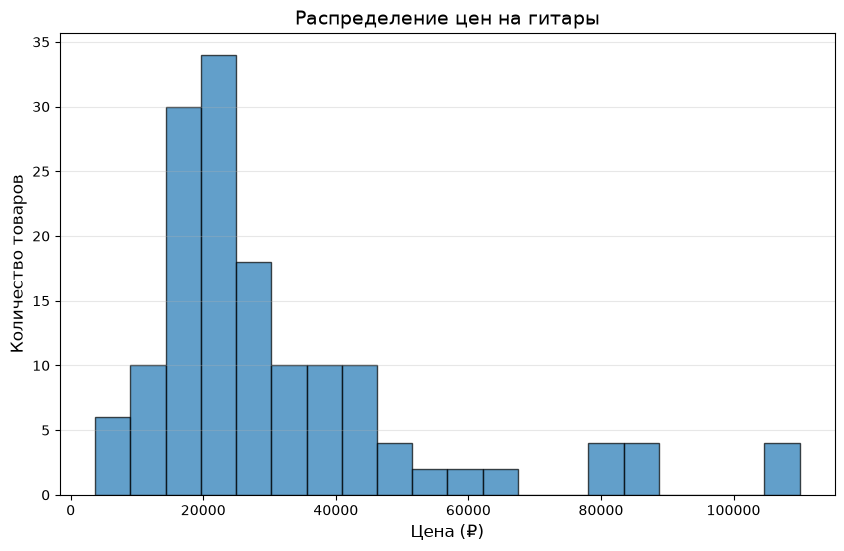

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

conn = psycopg2.connect(host="127.0.0.1", port=5433, dbname="test_db", user="admin", password="admin")
df_prices = pd.read_sql_query("SELECT price FROM products WHERE price IS NOT NULL", conn)

plt.figure(figsize=(10, 6))
plt.hist(df_prices['price'], bins=20, edgecolor='black', alpha=0.7)
plt.title('Распределение цен на гитары', fontsize=14)
plt.xlabel('Цена (₽)', fontsize=12)
plt.ylabel('Количество товаров', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.show()

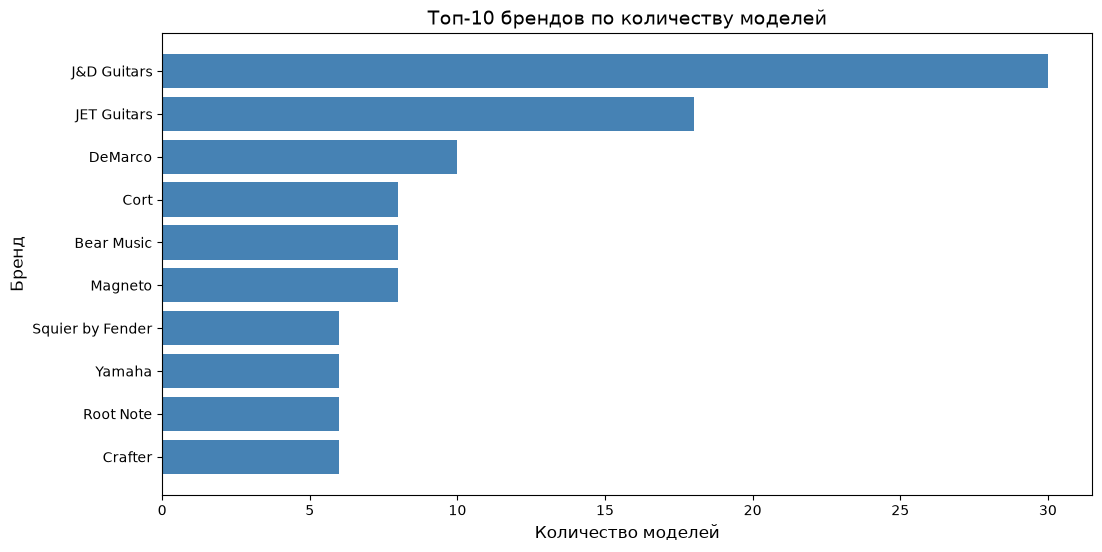

In [22]:
df_brands = pd.read_sql_query("""
    SELECT brand, COUNT(*) as count 
    FROM products 
    WHERE brand IS NOT NULL AND brand != 'UNKNOWN'
    GROUP BY brand 
    ORDER BY count DESC 
    LIMIT 10
""", conn)

plt.figure(figsize=(12, 6))
plt.barh(df_brands['brand'], df_brands['count'], color='steelblue')
plt.title('Топ-10 брендов по количеству моделей', fontsize=14)
plt.xlabel('Количество моделей', fontsize=12)
plt.ylabel('Бренд', fontsize=12)
plt.gca().invert_yaxis()  # Чтобы самый популярный был сверху
plt.show()

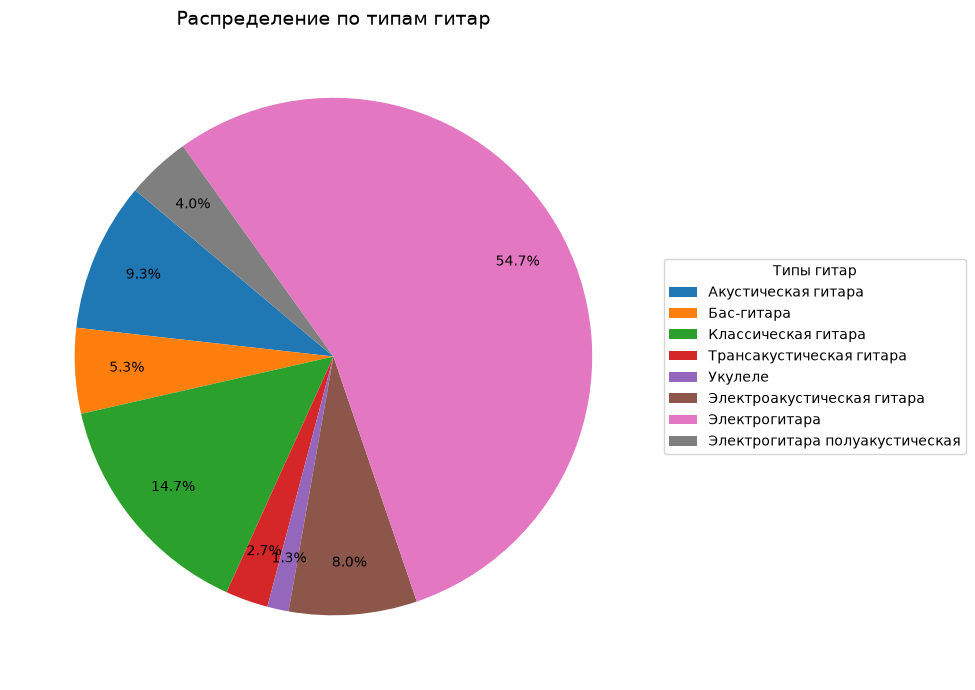

In [23]:
df_types = pd.read_sql_query("""
    SELECT pc.value AS guitar_type, COUNT(DISTINCT p.id) as count
    FROM products p
    JOIN product_characteristics pc ON p.id = pc.product_id
    WHERE pc.name = 'Тип'
    GROUP BY pc.value
""", conn)

plt.figure(figsize=(10, 7))

wedges, texts, autotexts = plt.pie(
    df_types['count'], 
    autopct='%1.1f%%', 
    startangle=140,
    pctdistance=0.8 # сдвигаем проценты ближе к краю, чтобы мелкие цифры не слипались в центре
)

plt.legend(
    wedges, 
    df_types['guitar_type'],
    title="Типы гитар",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1)
)

plt.title('Распределение по типам гитар', fontsize=14)
plt.tight_layout() # автоматически подгоняет отступы, чтобы легенда не обрезалась
plt.show()